# Error analysis
Comparison of the best custom model (`layer23_multihead_c256` with blur on the anomaly map) with PatchCore and PaDiM. 



In [4]:
from sklearn.metrics import roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np

CLASSES = ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw',
           'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
MODELS = ['custom', 'patchcore', 'padim']

# experiment folder and file suffix of each model (the custom model is evaluated with blur sigma 4)
EXPERIMENTS = {
    'custom': ('experiments/feature_reconstruction/layer23_multihead_c256', '_sigma4'),
    'patchcore': ('experiments/patchcore/resnet18', ''),
    'padim': ('experiments/padim/resnet18', ''),
}

FIGURES_DIR = Path('figures/error_analysis')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## **Part 1**: comparing quntitative results. 
This part doesn't require retraining models, it only reads the anomaly scores of each image saved into the log files (`image_scores*.csv`). The image score of each model is its main one: top-1% of the map for the custom model, the native score for PatchCore and PaDiM. For PatchCore and PaDiM, I also computed the anomly score as the top-1% of the map for a fair comparison with the custom model.

Mean over the 15 classes and selection metric per class ((Image AUROC + AUPRO) / 2, as for the ablations).

In [5]:
results = {model: pd.read_csv(Path(exp_dir) / f"overall_results{suffix}.csv", index_col=0)
           for model, (exp_dir, suffix) in EXPERIMENTS.items()}

summary = pd.DataFrame({model: df.loc['MEAN', ['image_auroc', 'pixel_auroc', 'aupro']] for model, df in results.items()}).T
summary['selection'] = (summary.image_auroc + summary.aupro) / 2
display(summary.round(4))

selection = pd.DataFrame({model: (df.loc[CLASSES, 'image_auroc'] + df.loc[CLASSES, 'aupro']) / 2
                          for model, df in results.items()})
selection['custom - patchcore'] = selection.custom - selection.patchcore
display(selection.sort_values('custom - patchcore').round(3))

,image_auroc,pixel_auroc,aupro,selection
custom,0.9622,0.9618,0.8992,0.9307
patchcore,0.9775,0.9782,0.9283,0.9529
padim,0.8813,0.9696,0.9212,0.9012


,custom,patchcore,padim,custom - patchcore
transistor,0.875,0.957,0.864,-0.082
tile,0.863,0.912,0.873,-0.049
toothbrush,0.869,0.918,0.882,-0.049
capsule,0.916,0.954,0.874,-0.038
zipper,0.922,0.955,0.907,-0.033
pill,0.906,0.937,0.897,-0.031
screw,0.934,0.958,0.818,-0.023
grid,0.921,0.941,0.897,-0.020
cable,0.943,0.959,0.835,-0.015
metal_nut,0.956,0.971,0.941,-0.015


## 1.1: Does the aggreragation method used for computing AUROC changes the model performance?

Compute image AUROC per class with the native score of PatchCore and PaDiM and with the top-1% score of the map, the same used by the custom model.

In [6]:
# Image AUROC with the native score and with the top-1% score of the map (for the custom model they coincide)
aggregation = pd.DataFrame({
    'custom (top-1%)': results['custom'].image_auroc,
    'patchcore native': results['patchcore'].image_auroc,
    'patchcore top-1%': results['patchcore'].image_auroc_top1pct,
    'padim native': results['padim'].image_auroc,
    'padim top-1%': results['padim'].image_auroc_top1pct,
}).loc[CLASSES + ['MEAN']]
display(aggregation.round(3))

,custom (top-1%),patchcore native,patchcore top-1%,padim native,padim top-1%
bottle,1.000,1.000,1.000,0.974,0.998
cable,0.992,0.979,0.995,0.771,0.857
capsule,0.933,0.983,0.981,0.838,0.902
carpet,0.989,0.984,0.979,0.986,0.989
grid,0.947,0.972,0.961,0.905,0.915
hazelnut,1.000,0.999,1.000,0.760,0.951
leather,1.000,1.000,1.000,1.000,1.000
metal_nut,1.000,0.998,0.997,0.951,0.981
pill,0.918,0.938,0.936,0.857,0.929
screw,0.918,0.947,0.955,0.720,0.681


Then, I create a table containing, for each image of the test set, the anomaly score assigned to that image by all the three methods cosidered for the error analysis, the class of the image and the defect type. Each image is identified by its path.

This will be useful later, for more fine-grained anlysis on specific defect types.

In [7]:
# One row per test image, one score column per model (the three files list the same images in the same order)
dfs = []
for cls in CLASSES:
    df = None
    for model, (exp_dir, suffix) in EXPERIMENTS.items():
        scores = pd.read_csv(Path(exp_dir) / cls / f"image_scores{suffix}.csv")
        if df is None:
            df = scores[['path', 'defect_type', 'label']].copy()
            df.insert(0, 'class', cls)
        df[model] = scores['score']
    dfs.append(df)
scores = pd.concat(dfs, ignore_index=True)

print(f"{len(scores)} test images, {scores.label.sum()} defective, "
      f"{scores[scores.label == 1].groupby('class').defect_type.nunique().sum()} defect types")
scores.head(50)

1725 test images, 1258 defective, 73 defect types


,class,path,defect_type,label,custom,patchcore,padim
0,bottle,data\MVTec\bottle\test\broken_large\000.png,broken_large,1,0.401745,2.949931,28.778664
1,bottle,data\MVTec\bottle\test\broken_large\001.png,broken_large,1,0.426898,3.246136,29.467432
2,bottle,data\MVTec\bottle\test\broken_large\002.png,broken_large,1,0.461326,2.755422,28.008366
3,bottle,data\MVTec\bottle\test\broken_large\003.png,broken_large,1,0.409694,3.274290,29.654379
4,bottle,data\MVTec\bottle\test\broken_large\004.png,broken_large,1,0.411353,3.298514,31.414206
5,bottle,data\MVTec\bottle\test\broken_large\005.png,broken_large,1,0.441512,2.987136,28.285868
6,bottle,data\MVTec\bottle\test\broken_large\006.png,broken_large,1,0.426642,3.420663,29.166142
7,bottle,data\MVTec\bottle\test\broken_large\007.png,broken_large,1,0.378280,2.744619,27.104639
8,bottle,data\MVTec\bottle\test\broken_large\008.png,broken_large,1,0.408273,3.078273,34.607471
9,bottle,data\MVTec\bottle\test\broken_large\009.png,broken_large,1,0.331369,2.707739,26.237610


- PatchCore is the best model on every metric. The custom model is close to PatchCore in detection (Image AUROC 0. 962 vs 0.978): the gap is mostly in
  localization (AUPRO 0.899 vs 0.928). Localization is its weak point: even PaDiM, much worse in detection,
  has a higher AUPRO in 12 classes out of 15.
- The gap is concentrated in a few classes: transistor (-0.082, AUPRO 0.79 vs 0.93), tile, toothbrush and capsule.
  On the textures (carpet, wood, leather) and on bottle the custom model is on par or slightly better.
- The low Image AUROC of PaDiM (0.881) comes from its native score (the maximum of the map): with the top-1% score it
  rises to 0.930. The top-1% score is better in almost every class, with the largest gains on hazelnut, transistor, toothbrush and cable; screw is the only class where it is worse.
- For PatchCore the two scores are almost equivalent, with a larger difference only on toothbrush.
- With the same aggregation (top-1%) the ranking does not change: PatchCore 0.982, custom 0.962, PaDiM 0.930.

## 1.2: Which defect types are hard for **all** models (intrinsic difficulty of the data)?
To answer this question I compute the image AUROC for each defect type

In [8]:
rows = []
for (cls, defect_type), group in scores[scores.label == 1].groupby(['class', 'defect_type']):
    good = scores[(scores['class'] == cls) & (scores.label == 0)]
    both = pd.concat([good, group])
    row = {'class': cls, 'defect_type': defect_type, 'n_images': len(group)}
    for model in MODELS:
        row[model] = roc_auc_score(both.label, both[model])
    rows.append(row)
defect_auroc = pd.DataFrame(rows).set_index(['class', 'defect_type'])

pd.set_option('display.max_rows', 100)
display(defect_auroc.round(3))

n_images  custom  patchcore  padim
class      defect_type                                             
bottle     broken_large                20   1.000      1.000  1.000
           broken_small                22   1.000      1.000  1.000
           contamination               21   1.000      1.000  0.988
cable      bent_wire                   13   1.000      1.000  0.972
           cable_swap                  12   0.941      0.881  0.701
           combined                    11   1.000      1.000  0.903
           cut_inner_insulation        14   1.000      0.990  0.879
           cut_outer_insulation        10   1.000      0.993  0.979
           missing_cable               12   1.000      1.000  0.588
           missing_wire                10   0.993      0.997  0.626
           poke_insulation             10   1.000      0.976  0.878
capsule    crack                       23   0.930      0.977  0.898
           faulty_imprint              22   0.879      0.988  0.767
           poke                        21   0.940      0.994  0.834
           scratch                     23   0.924      0.960  0.866
           squeeze                     20   1.000      1.000  0.948
carpet     color                       19   1.000      1.000  0.985
           cut                         17   1.000      1.000  1.000
           hole                        17   1.000      1.000  1.000
           metal_contamination         17   0.964      0.945  0.983
           thread                      19   0.979      0.976  0.964
grid       bent                        12   0.992      0.992  0.881
           broken                      12   1.000      1.000  1.000
           glue                        11   0.857      0.900  0.766
           metal_contamination         11   0.957      0.987  0.965
           thread                      11   0.922      0.978  0.905
hazelnut   crack                       18   1.000      1.000  0.754
           cut                         17   1.000      0.996  0.818
           hole                        18   1.000      1.000  0.929
           print                       17   1.000      1.000  0.806
leather    color                       19   1.000      1.000  1.000
           cut                         19   1.000      1.000  1.000
           fold                        17   1.000      1.000  1.000
           glue                        19   1.000      1.000  1.000
           poke                        18   1.000      1.000  1.000
metal_nut  bent                        25   1.000      1.000  0.975
           color                       22   1.000      0.996  0.965
           flip                        23   1.000      1.000  1.000
           scratch                     23   1.000      0.996  0.897
pill       color                       25   0.900      0.914  0.945
           combined                    17   0.980      0.991  0.982
           contamination               21   0.969      0.989  0.919
           crack                       26   0.803      0.848  0.756
           faulty_imprint              19   0.984      0.966  0.783
           pill_type                    9   1.000      1.000  0.940
           scratch                     24   0.888      0.934  0.787
screw      manipulated_front           24   0.858      0.899  0.847
           scratch_head                24   0.962      0.972  0.716
           scratch_neck                25   0.987      0.986  0.653
           thread_side                 23   0.824      0.902  0.667
           thread_top                  23   0.952      0.973  0.714
tile       crack                       17   1.000      1.000  1.000
           glue_strip                  18   1.000      1.000  1.000
           gray_stroke                 16   0.936      0.973  0.805
           oil                         18   1.000      1.000  0.995
           rough                       15   0.923      0.992  0.954
toothbrush defective                   30   0.892      0.931  0.881
transistor bent_lead 

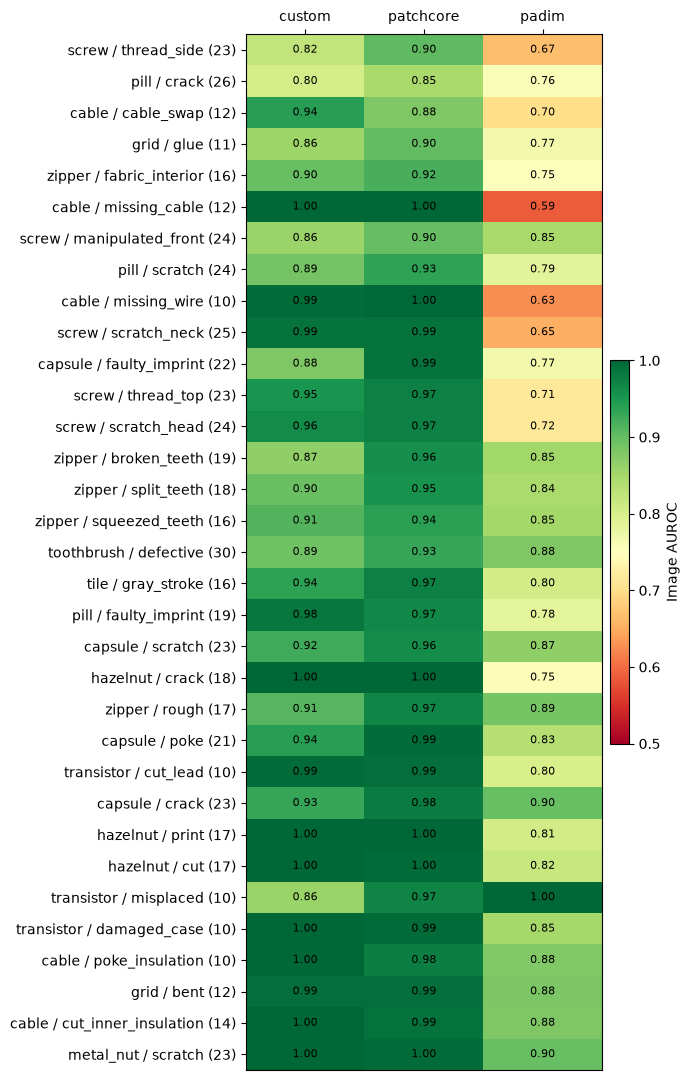

In [9]:
# Heatmap of the defect types where at least one model is below 0.9
hard = defect_auroc[defect_auroc[MODELS].min(axis=1) < 0.9]
hard = hard.loc[hard[MODELS].mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7, 0.3 * len(hard) + 1))
im = ax.imshow(hard[MODELS].values, cmap='RdYlGn', vmin=0.5, vmax=1.0, aspect='auto')
for i in range(len(hard)):
    for j, model in enumerate(MODELS):
        ax.text(j, i, f"{hard[model].iloc[i]:.2f}", ha='center', va='center', fontsize=8)
ax.set_xticks(range(len(MODELS)), MODELS)
ax.set_yticks(range(len(hard)), [f"{c} / {d} ({n})" for (c, d), n in zip(hard.index, hard.n_images)])
ax.xaxis.tick_top()
plt.colorbar(im, ax=ax, fraction=0.05, pad=0.02, label='Image AUROC')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'defect_type_auroc.png', dpi=200, bbox_inches='tight')
plt.show()

- Most defect types are easy for the custom model and PatchCore; the hard ones are concentrated in screw, pill,
  zipper, capsule and grid, i.e. small defects or objects with a variable pose.
- Largest gaps of the custom model with respect to PatchCore: transistor/misplaced,capsule/faulty_imprint, zipper/broken_teeth, screw/thread_side. The custom model is significantly better only on cable/cable_swap.
- transistor/misplaced is a "global" anomaly (the component is missing or shifted): each patch may look normal
  locally, the anomaly is in what is expected at that position. PaDiM, which fits a Gaussian per position, detects it perfectly.
- It's important to note that each defect type could have very few test images: a single image can change the AUROC significantly, so only large differences are meaningful.

## 1.3: Defect types that are likely to be inherently difficult
I assume that defect types that are hard for every method (AUROC < 0.9 for each of them), are those for which the difficulty comes from the data itself rather than the method used.

In [10]:
print("Defect types hard for all the models (Image AUROC < 0.9 for each of them):")
display(defect_auroc[defect_auroc[MODELS].max(axis=1) < 0.9].round(3))

Defect types hard for all the models (Image AUROC < 0.9 for each of them):


,,n_images,custom,patchcore,padim
class,defect_type,,,,
pill,crack,26,0.803,0.848,0.756
screw,manipulated_front,24,0.858,0.899,0.847


Only two defect types are below 0.9 for all three models: pill/crack and screw/manipulated_front. They are the best candidates for an intrinsic difficulty of the data: thin cracks on a pill surface that is speckled also in the normal images, and a subtle deformation of the screw tip, with a screw orientation that changes from image to image.

## 1.4. False positives and false negatives
Threshold at the maximum F1 on the test set, per class and per model (the choice of anomalib's PostProcessor,
which picks it on the validation set, by default the test set). The threshold is chosen on the test set, so it is
optimistic: it is only used to count and compare the errors, not as a performance metric.

In [11]:
def f1_threshold(labels, image_scores):
    precision, recall, thresholds = precision_recall_curve(labels, image_scores)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]  # the last point (recall 0) has no threshold


for model in MODELS:
    thresholds = scores.groupby('class').apply(lambda g: f1_threshold(g.label, g[model]))
    predicted = scores[model] >= scores['class'].map(thresholds)
    scores[f"{model}_wrong"] = predicted != scores.label.astype(bool)

errors = pd.DataFrame({
    model: {'false positives': (scores[f"{model}_wrong"] & (scores.label == 0)).sum(),
            'false negatives': (scores[f"{model}_wrong"] & (scores.label == 1)).sum()}
    for model in MODELS
}).T
display(errors)

,false positives,false negatives
custom,59,34
patchcore,41,34
padim,151,42


The custom model misses as many defective images as PatchCore, its extra errors are false alarms on good images. PaDiM has many more false positives, I suppose monstly due to its native scoring of the anomaly map. I think that using the top-1% scoring it could be better